# Pearson residuals and scTransform

*Python port of the R vignette [Pearson residuals and scTransform](https://gregorlueg.github.io/bixverse/articles/single_cell_residuals.html). Original author: Gregor Lueg.*

## Intro

`bixverse` normalises once, at ingestion. Counts go in, `log1p(count / lib_size
* target_size)` comes out, and both layers sit on disk from then on. Every
downstream step reads that second layer. It's cheap, it streams, and it is why
a million cells fit on a laptop.

It also has a known problem. Library-size normalisation followed by a log
assumes the variance of a gene is roughly constant once you've divided the depth
out. For UMI counts that isn't true. Highly expressed genes carry more variance
than lowly expressed ones no matter what you divide by, so a variance-based HVG
ranking partly ranks genes by how much they were expressed in the first place.

Pearson residuals fix this by asking a different question. Fit a null model of
what a gene's counts should look like given only sequencing depth, then ask how
far each cell deviates from it:

$$
r_{gc} = \frac{y_{gc} - \mu_{gc}}{\sqrt{\mu_{gc} + \mu_{gc}^2 / \theta_g}}
$$

A gene that is nothing but depth gets residuals with variance near one. A gene
with real structure gets more. As an HVG statistic that holds up well. As a PCA
input it's more contested, and
[the caveats section](#what-the-field-actually-thinks) goes through what the
benchmarks actually say.

The catch is cost. Nothing about this is precomputable: a residual depends on
the fitted model, so it has to be regenerated every time something wants it.
Worse, a residual is non-zero even where the count is zero, so the matrix is
dense by construction. That is exactly the trade-off the
[design vignette](design_single_cell.ipynb) warns about, and it's why this is
opt-in rather than the default.

`bixverse` gives you two flavours.

- **scTransform v2** ([Choudhary and Satija, 2022](https://doi.org/10.1186/s13059-021-02584-9))
fits a negative binomial per gene by regression against log depth, then
regularises the per-gene parameters against their expression level with a kernel
smoother. Only a bounded subsample (2000 genes by 2000 cells by default) goes
through the actual GLM fitting, so the expensive part doesn't scale with your
data set. Everything after it streams.

- **Analytic Pearson residuals** ([Lause, Berens and Kobak, 2021](https://doi.org/10.1186/s13059-021-02451-7))
skip the fitting entirely. One shared dispersion for every gene, and $\mu$ from
the marginals: $\mu_{gc} = \frac{\sum_c y_{gc} \cdot \sum_g y_{gc}}{\sum_{gc} y_{gc}}$.
Closed form, no iterations, and their paper argues it ranks genes about as well
as the fitted version does.

Analytic Pearson is the one to reach for first. It's a couple of orders of
magnitude cheaper and you can always refit with scTransform if you need
corrected counts or per-gene dispersions.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import HvgParams, PcaParams

## Loading the data

Two PBMC runs, so there's something to group over later.

In [2]:
dir_data = bv.io.download_pbmc_batches()

tempdir_resid = tempfile.TemporaryDirectory()

h5ad_paths = {
    "pbmc3k": dir_data / "pbmc3k.h5ad",
    "pbmc4k": dir_data / "pbmc4k.h5ad",
}

h5_tasks = bv.io.prescan_h5ad_files(h5ad_paths)

sc = bv.io.load_multi_h5ad(Path(tempdir_resid.name) / "residuals", h5_tasks)

Standard QC before anything else. A residual model fitted on debris is a model
of debris.

In [3]:
h5_metadata = bv.io.read_h5ad_metadata(h5ad_paths["pbmc3k"])

var = sc.var().join(
    h5_metadata["var"].select("gene_id", pl.col("symbol_tenx").alias("gene_symbol")),
    on="gene_id",
)

gs_of_interest = {
    "MT": var.filter(pl.col("gene_symbol").str.contains("^MT-"))["gene_id"].to_list(),
    "Ribo": var.filter(pl.col("gene_symbol").str.contains("^RP[SL]"))[
        "gene_id"
    ].to_list(),
}

bv.qc.gene_set_proportions(sc, gs_of_interest, streaming=False)

qc_df = sc.obs(cols=["cell_id", "lib_size", "nnz", "MT"])

qc = bv.qc.run_cell_qc(
    {
        "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
        "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
        "MT": qc_df["MT"].to_numpy(),
    },
    sc.cells_to_keep,
    directions={
        "log10_lib_size": "twosided",
        "log10_nnz": "twosided",
        "MT": "above",
    },
    threshold=3.0,
)

sc.add_obs(pl.DataFrame({"cell_idx": qc.cell_idx, "outlier": qc.combined}))
sc.set_cells_to_keep(qc.cell_idx[~qc.combined])

sc

SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpdfj3ssq9/residuals',
  cells=7040 (kept 6626), genes=13925,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

## Fitting a model

`fit_residuals()` fits and caches. It doesn't transform anything, and it
doesn't touch the counts on disk. What lands on the object is the model, in
`sc.cache.residual_fit`.

In [4]:
bv.pp.fit_residuals(sc, method="analytic_pearson", verbose=True)

fit = sc.cache.residual_fit

print(
    f"{fit.method}: {fit.n_groups} model(s), {fit.genes.size} genes, "
    f"{fit.cell_indices.size} cells"
)

Analytic Pearson: swept 13_925 genes in 18.70ms, 13_925 pass the min_cells filter
analytic_pearson: 1 model(s), 13925 genes, 6626 cells


The fit is keyed to the cells it saw. Move the filter afterwards and anything
that tries to use it errors rather than quietly applying coefficients to the
wrong cells. The usual cache-status machinery knows about it too:

In [5]:
sc.cache_status()

artefact,stamped,stale,reason,id,parents
str,bool,bool,str,str,list[str]
"""residuals""",true,false,null,"""2e6a3f9a09a041b9""",[]


## Variable features

`find_hvg()` gains a `"residual"` method. It ranks on the residual variance
of the cached model instead of on the stored layer.

In [6]:
bv.pp.find_hvg(
    sc,
    hvg_no=2000,
    hvg_params=HvgParams(method="residual"),
    verbose=True,
)

sc.map.hvg.size

Residual variance for 13_925 gene(s) across 1 group(s) in 57.80ms


2000

The per-gene statistic lands in the variable table as `residual_variance`.
Genes the model didn't retain come back null rather than zero, which matters:
zero would read as a real measurement of no variance.

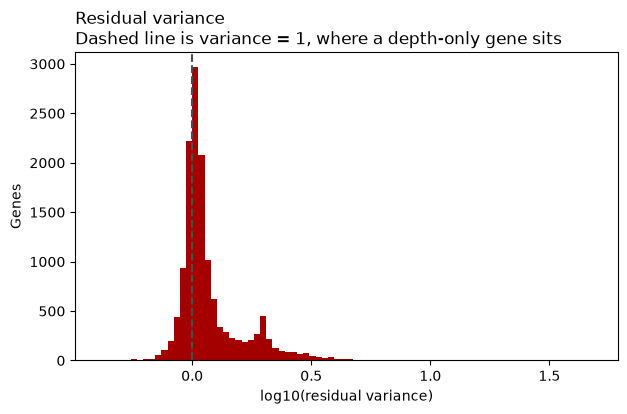

In [7]:
res_var = sc.var()["residual_variance"].drop_nulls().to_numpy()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(np.log10(res_var), bins=80, color=bv.pl.bx_colors("main", n=1)[0])
ax.axvline(0, linestyle="--", color="0.3")
ax.set_title(
    "Residual variance\nDashed line is variance = 1, where a depth-only gene sits",
    loc="left",
)
ax.set_xlabel("log10(residual variance)")
ax.set_ylabel("Genes")
plt.show()

That bulk piled up around one is the null doing its job. The tail to the right
is what you actually want to cluster on.

Worth comparing against what the default ranking picks. `find_hvg()` writes to
the experiment, so we keep the residual selection, run `"vst"` and put the
residual one back afterwards.

In [8]:
hvg_residual = sc.map.hvg.copy()

bv.pp.find_hvg(sc, hvg_no=2000, hvg_params=HvgParams(method="vst"))

hvg_vst = sc.map.hvg.copy()

sc.map.hvg = hvg_residual

n_shared = np.intersect1d(hvg_residual, hvg_vst).size

print(f"{n_shared} of 2000 genes shared ({100 * n_shared / 2000:.0f}%)")

1537 of 2000 genes shared (77%)


Substantial overlap, and the disagreement is the interesting part. The residual
ranking tends to favour lower-expressed markers that a variance ranking buries
under housekeeping genes.

## PCA on residuals

`calculate_pca()` takes `residuals=True`. Two settings have to change, and
the function will tell you so rather than silently working around you:

In [9]:
try:
    bv.pp.calculate_pca(sc, no_pcs=30, residuals=True)
except ValueError as e:
    print(e)

Residual PCA cannot normalise the variance: the residuals already carry the biological signal as variance, and scaling it away is the one thing the transform exists to avoid. Pass PcaParams(normalise_variance=False).


Variance normalisation is on by default, and on this path it would flatten the
exact ranking the transform produces. The `PFlogPF` transform belongs to the
normalised layer and has nothing to say about residuals. Both are refused
rather than overridden, because they're settings you passed and quietly changing
them would make the recorded parameters a lie.

In [10]:
bv.pp.calculate_pca(
    sc,
    no_pcs=30,
    pca_params=PcaParams(normalise_variance=False),
    residuals=True,
    verbose=True,
)

sc.cache.pca_factors.shape

PCA: Loaded in data in 4.01ms


PCA: Finished scaling in 20.71ms


PCA: Finished calculations in 747.67ms
PCA: Total run time -> 772.49ms


(6626, 30)

From here it's the normal pipeline. Neighbours, clusters, embeddings, none of
them know or care where the PCA came from.

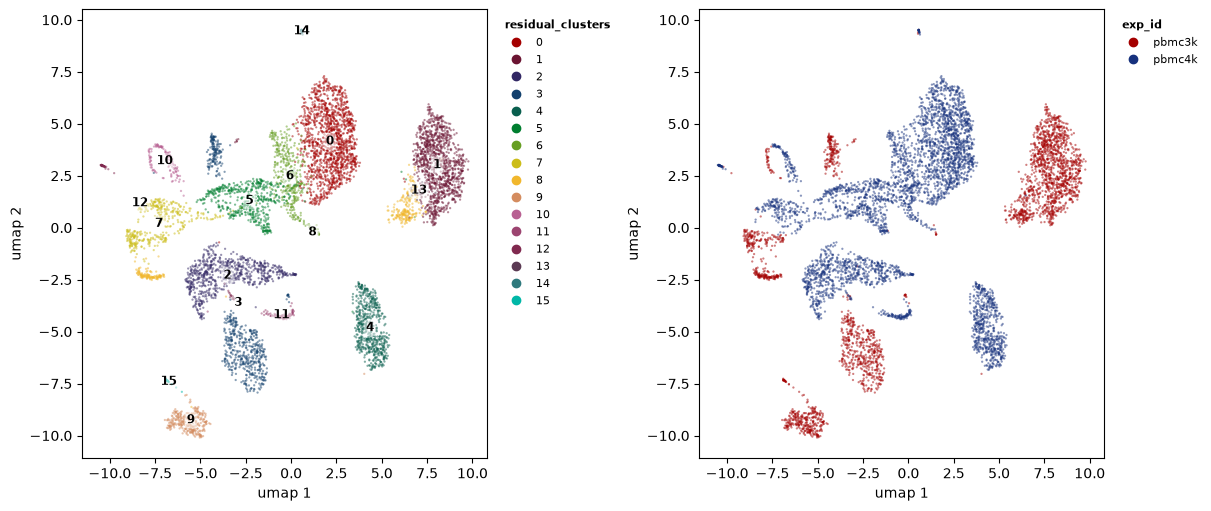

In [11]:
bv.graph.find_neighbours(sc)
bv.graph.find_clusters(sc, res=0.8, name="residual_clusters")
bv.embed.umap(sc)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
bv.pl.embedding_plot(
    sc,
    "umap",
    "residual_clusters",
    label_by="residual_clusters",
    discrete=True,
    ax=axes[0],
)
bv.pl.embedding_plot(sc, "umap", "exp_id", discrete=True, ax=axes[1])
plt.show()

The right panel is worth a look: the two runs (different chemistries) sit
apart. Residuals take the depth out, not the batch. More on that below.

### What it costs

The residual path has no sparse solver and no streaming solver. A residual
column is dense even where the counts are not, because a zero count still has a
residual of `-mu / sqrt(var)`. So the PCA input is a real cells by genes dense
matrix, and `calculate_pca()` warns once it gets past a few gigabytes.

Two knobs if that bites: fewer HVGs, or fewer cells. There's no third option,
and `sparse_svd=True` errors rather than silently running the log-normalised
algorithm instead.

## Multi-sample fits

Fitting one model across several samples folds their depth differences into the
gene coefficients. `group_column` fits one model per group instead, which is
what Seurat v5 does with split layers.

The fit lives on the experiment, so a second fit replaces the first. We keep
going on the same object from here and refit each time.

In [12]:
bv.pp.fit_residuals(
    sc,
    method="analytic_pearson",
    group_column="exp_id",
    verbose=True,
)

fit_grouped = sc.cache.residual_fit

print(
    f"{fit_grouped.method}: {fit_grouped.n_groups} model(s), "
    f"{fit_grouped.genes.size} genes (ungrouped: {fit.genes.size})"
)

Analytic Pearson: swept 13_925 genes in 14.25ms, 12_223 pass the min_cells filter
Analytic Pearson: group 0 fitted over 2_611 cells, 12_223 genes (17.28ms)
Analytic Pearson: swept 13_925 genes in 17.39ms, 13_843 pass the min_cells filter
Analytic Pearson: group 1 fitted over 4_015 cells, 13_843 genes (40.52ms)
analytic_pearson: 2 model(s), 12155 genes (ungrouped: 13925)


The gene axis narrows to the intersection: a gene one sample filtered out is not
modelled anywhere, because there'd be no coefficients to apply to that sample's
cells.

Grouping also changes what `hvg_no` means. Seurat's rule is to rank within each
sample, take the top N of each, then union them, so a marker that only one
sample carries doesn't get buried by a pooled ranking. The result is therefore
usually **more** than `hvg_no` genes:

In [13]:
bv.pp.find_hvg(
    sc,
    hvg_no=2000,
    hvg_params=HvgParams(method="residual"),
    verbose=True,
)

sc.map.hvg.size

Residual variance for 12_155 gene(s) across 2 group(s) in 85.37ms


3404

`bixverse` doesn't trim that back to 2000. Trimming would undo the per-sample
ranking, which is the only reason to do the union in the first place.

One thing this is not: batch correction. Per-sample models remove the
sample-level depth differences, not the batch effect. If the batches still don't
mix, you want the batch correction tools in `bv.integrate`, see the
[batch correction vignette](single_cell_batch_corrections.ipynb).

## Covariates

scTransform can take extra cell-level covariates into the design. Library size
is never one of them: it enters as a fixed offset with the slope pinned, which
is the change that separates v2 from v1.

In [14]:
bv.pp.fit_residuals(
    sc,
    method="sctransform",
    covariate_columns=["MT"],
    verbose=True,
)

sc.cache.residual_fit.covariate_names

scTransform: swept 13_925 genes in 25.00ms, 13925 pass the min_cells filter
scTransform: step-1 fit on 2_000 genes by 2_000 cells


scTransform: fitted 2_000 genes with 2 coefficient(s) in 2.02s


('MT',)

The design holds the intercept and the one covariate.

Column **order** is remembered and checked on every later use. Hand the model a
reordered set and it errors instead of applying each coefficient to the wrong
column, which would give you plausible-looking residuals and a wrong embedding.

Numeric columns only. A categorical needs dummy coding, and `bixverse`
refuses to guess a contrast for you rather than silently changing the rank of
the design matrix.

## Corrected counts

Residuals are a modelling device. They are not counts, they go negative, and
nothing downstream that expects counts will take them. `sct_corrected_counts()`
reverses the transform with every latent variable held at its median, which
removes the depth structure while keeping the per-sample intercept.

In [15]:
bv.pp.fit_residuals(sc, method="sctransform", verbose=True)

corrected = bv.pp.sct_corrected_counts(
    sc,
    dir_out=Path(tempdir_resid.name) / "pbmc_corrected",
    verbose=True,
)

corrected

scTransform: swept 13_925 genes in 23.84ms, 13925 pass the min_cells filter
scTransform: step-1 fit on 2_000 genes by 2_000 cells


scTransform: fitted 2_000 genes with 1 coefficient(s) in 887.09ms


scTransform: wrote 13_925 corrected genes in 266.77ms
Transpose: 13_925 genes by 6_626 cells, 1 phase(s)
Transpose: wrote the cell-major store in 189.63ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpdfj3ssq9/pbmc_corrected',
  cells=6626 (kept 6626), genes=13925,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

That comes back as a proper `SingleCells`, not a loose file. Behind the scenes
the gene-major store gets written, transposed into its cell-major twin, and
given a fresh database.

Two things to know about it. It's scTransform only, since the analytic Pearson
model has no corrected-count equivalent. And its gene axis is the **model's**,
so whenever the model drops genes (the `min_cells` filter, or the intersection
of a grouped fit) it is narrower than the source and the indices do not line
up. The variable table is rebuilt from the genes that survived rather than
copied across, so gene names are right; raw index arithmetic against the
original object is not. On this data every gene passes the filter of an
ungrouped fit, so the two happen to match:

In [16]:
print(f"source: {sc.var().height} genes, corrected: {corrected.var().height} genes")

source: 13925 genes, corrected: 13925 genes


## What the field actually thinks

Residuals are not a settled win, and it would be dishonest to ship them here
without saying so. Three findings are worth knowing before you build an analysis
on them.

### The transform is not monotonic

This is the sharpest criticism, and it comes from
[Booeshaghi, Hallgrímsdóttir, Gálvez-Merchán and Pachter](https://www.biorxiv.org/content/10.1101/2022.05.06.490859v4).
A residual is a signed distance from a per-gene null, so two genes in the same
cell can swap places relative to their raw counts. The transform reorders genes
*within* a cell.

That matters more than it sounds. Marker inspection, heatmaps and anything that
reads "gene A is higher than gene B in this cell" are answering a question about
the transformed values, not about the counts. Their benchmark across 526 data
sets found residual and scaling transformations showed exactly these within-cell
rank changes, and that sctransform retained substantial depth correlation in
many of them, which is awkward for a method whose stated job is removing depth.

Their proposal is `PFlogPF`, a shifted centred-log-ratio transform that keeps
monotonicity. `bixverse` has it as `PcaParams(clr=True)` on the normal
path, and it is a reasonable thing to try before reaching for residuals at all.

### The benchmarks are not one-sided

[Ahlmann-Eltze and Huber](https://doi.org/10.1038/s41592-023-01814-1) compared
delta-method, residual, latent-state and factor-analysis transformations in
Nature Methods and found that the plain shifted logarithm followed by PCA
performs as well or better than the sophisticated alternatives on simulated and
real data. They did single out analytic Pearson residuals as well suited to
picking variable genes and finding rare cell types, which is a narrower claim
than "use residuals for everything".

That shape matches what's implemented here. Using residuals to *choose* genes
and then running the normal pipeline is a defensible middle ground, and
`find_hvg(hvg_params=HvgParams(method="residual"))` followed by an
ordinary `calculate_pca()` does exactly that.

### scTransform v1 was overfitted

[Lause, Berens and Kobak](https://doi.org/10.1186/s13059-021-02451-7) showed the
original model is overspecified: per-gene overdispersion estimates come out
strongly biased, which is why the method needs a post-hoc smoothing step to be
usable at all. Their argument is that UMI data don't need gene-specific
overdispersion in the first place.

v2 addresses a good chunk of this by pinning the depth coefficient rather than
fitting it, and it is the version implemented here. The regularisation is still
doing real work though, and `bw_adjust` in `SctransformParams` is the knob
that controls how much.

### Scaling

The dense-matrix problem from "What it costs" above is the same one the Pachter
paper raises: dense residual output is what makes million-cell analyses
awkward, since the whole point of the on-disk sparse format is that you never
materialise a matrix that size.

`bixverse` softens this but does not solve it. The fit and the variance sweep
both stream gene by gene, so memory there is one row per worker rather than a
genes-by-cells matrix, and the scTransform GLM only ever sees a bounded 2000 by
2000 subsample. Those parts scale fine. The residual PCA does not, because a
dense SVD needs a dense input. At a million cells you can still fit a model and
select genes on residuals; you cannot run the residual PCA, and
`calculate_pca()` will warn you with the actual number before it tries.

### So what should you use

Analytic Pearson for gene selection, then the normal log-normalised PCA, is the
combination with the least to argue against it. Full residual PCA is worth
trying when you suspect depth is driving your embedding, and worth checking
against the default rather than trusting blindly. If you want marker-level
interpretability, stay on the normalised layer or use `PFlogPF`.

## Where to go next

Meta cells take all of this too. Their counts are summed UMIs, so the negative
binomial still applies, just at far greater depth. Prefer
`method="analytic_pearson"` there and revisit the `n_genes` and `n_cells`
defaults of `SctransformParams`, which are sized for raw cells and there
are usually a lot more of those than there are meta cells.

Still on the list: residual-space projection of new cells onto existing
components, which the Rust side can already do but has no Python entry point
yet.

## Clean up

In [17]:
tempdir_resid.cleanup()